# Bivariate data - Models

This tutorial focuses on fitting simple regression models to bivariate data using `plans`, and assessing them with the model panel and fit metrics.

```{seealso}
Check out the {doc}`Bivariate data - Basics <bivar_01>` tutorial first.
```

## Notebook setup

For users running this tutorial as a Jupyter Notebook, this cell must be executed first:

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd

# Install `plans` in `google.colab`.
# Use `pip install plans` for other environments.

if "google.colab" in sys.modules:
    import os
    os.system(f"{sys.executable} -m pip install -q plans")

# This avoids warnings related to uninstalled fonts
import logging
# Set the matplotlib font manager logger to only show errors (hides warnings)
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

# define output folder
OUTPUT_DIR = Path("outputs/bivariate")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Outputs will be saved to: ./{OUTPUT_DIR}")

Outputs will be saved to: ./outputs\bivariate


## Create synthetic rating curve

Stage-discharge relations (rating curves) are a classic case for model fitting in hydrology. Discharge usually starts at a stage offset (the gauge zero is below the channel bottom), so lets make one with $h_0 = 0.2$ m plus gaussian noise. Stages are drawn from a skewed (gamma) distribution, since low flows are far more frequent than floods in a real gauging record:

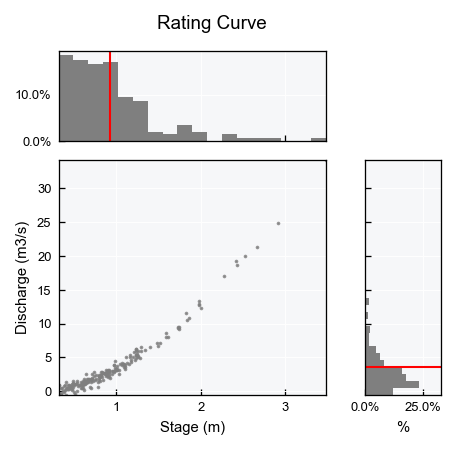

In [2]:
from plans.datasets.analyst import Bivar

# make synthetic power-law data with a stage offset
rng = np.random.default_rng(seed=42)  # ensure reproducibility
h = 0.3 + rng.gamma(shape=1.5, scale=0.4, size=200)  # skewed to low stages
q = 5 * np.power(h - 0.2, 1.6) + rng.normal(loc=0, scale=0.5, size=len(h))

bv = Bivar(name="Rating Curve", alias="RC")
bv.xname = "Stage"
bv.xunits = "m"
bv.yname = "Discharge"
bv.yunits = "m3/s"
bv.set_data(x=h, y=q)
bv.view()

## Available models

Models are stored in the `.models` dictionary. Each entry holds the function, its formula, a `Setup` table of parameters (initial guesses before fitting) and, once computed, the model `Data` and `Metrics`:

In [3]:
for model_type, model in bv.models.items():
    print(f"{model_type:<12} {model['Formula']}")

Linear       f(x) = c0 + c1 * x
Power        f(x) =  c2 * ((x + c0)^c1)
Power_zero   f(x) =  c1 * (x^c0)


## Fitting models

The `.fit()` method runs a least squares fit and stores the mean and standard deviation of parameters in the `Setup` table. The `model` layout shows the fitted curve, how the error variance evolves along `x`, the errors, their histogram and a Q-Q plot against the normal distribution.

### Linear model

The simplest model. A straight line can not follow the curvature, so errors show a clear pattern along `x`:

In [4]:
bv.fit(model_type="Linear")
print(bv.models["Linear"]["Formula"])
bv.models["Linear"]["Setup"]

f(x) = c0 + c1 * x


,Parameters,Mean,SD
0,c0,-4.373973,0.181619
1,c1,8.632297,0.171988


Fit metrics:

In [5]:
bv.models["Linear"]["Metrics"]

{'r': 0.9628756752076764,
 'rho': 0.9634260856521415,
 'R2': 0.9271295659066388,
 'RMSE': 1.2349857669571258,
 'MAE': 0.919012840087451,
 'Bias': 2.4696790784111732e-08}

Model panel:

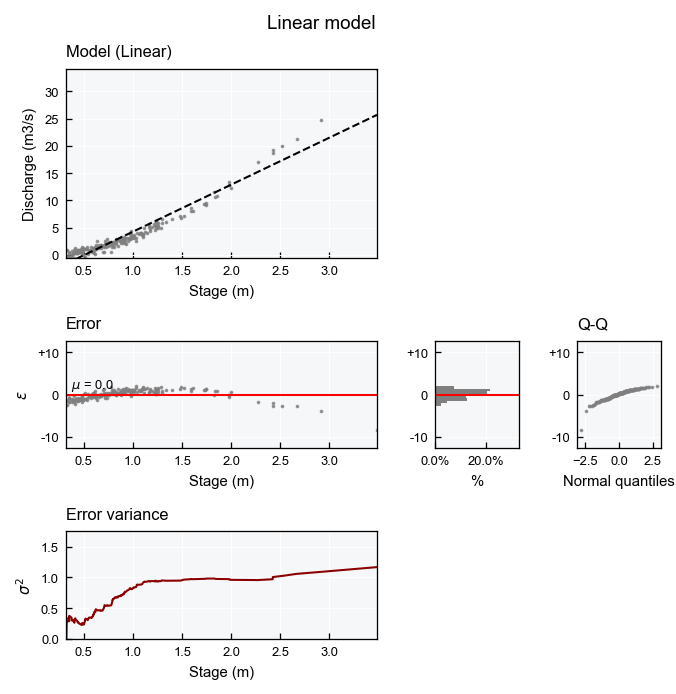

In [6]:
bv.view_specs["layout"] = "model"
bv.view_specs["model_type"] = "Linear"
bv.view_specs["title"] = "Linear model"
bv.view()

The model `Data` holds the predictions (`y_Mean`) and the errors (`e_Mean`, model minus observed):

In [7]:
bv.models["Linear"]["Data"].head()

,x,y,y_Mean,e_Mean
0,0.317913,-0.180704,-1.629649,-1.448945
1,0.318673,-0.315874,-1.623089,-1.307215
2,0.323125,0.857127,-1.584662,-2.441789
3,0.325952,0.987234,-1.560258,-2.547492
4,0.344702,-0.217002,-1.398398,-1.181397


### Power_zero model

A power law with root at zero. It follows the curvature, but can not represent the stage offset:

In [8]:
bv.fit(model_type="Power_zero")
print(bv.models["Power_zero"]["Formula"])
bv.models["Power_zero"]["Setup"]

f(x) =  c1 * (x^c0)


,Parameters,Mean,SD
0,c0,1.873139,0.014986
1,c1,3.431515,0.043597


Fit metrics:

In [9]:
bv.models["Power_zero"]["Metrics"]

{'r': 0.9935712183494392,
 'rho': 0.9634260856521415,
 'R2': 0.9867430899580296,
 'RMSE': 0.5267534985525234,
 'MAE': 0.4079012884384201,
 'Bias': 2.0582720823796645}

Model panel:

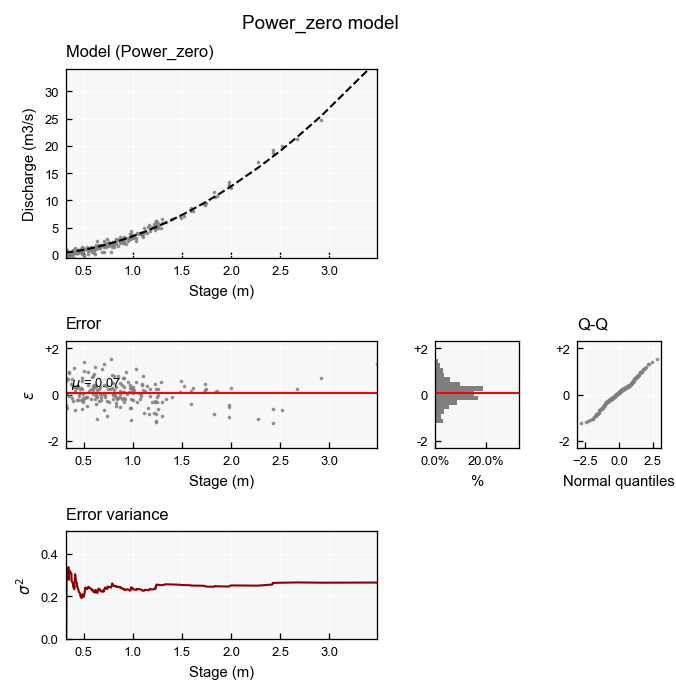

In [10]:
bv.view_specs["layout"] = "model"
bv.view_specs["model_type"] = "Power_zero"
bv.view_specs["title"] = "Power_zero model"
bv.view()

### Power model

A power law with a translational parameter `c0`, which captures the stage offset ($c_0 \approx -h_0$):

In [11]:
bv.fit(model_type="Power")
print(bv.models["Power"]["Formula"])
bv.models["Power"]["Setup"]

f(x) =  c2 * ((x + c0)^c1)


,Parameters,Mean,SD
0,c0,-0.184590,0.030121
1,c1,1.655100,0.038360
2,c2,4.789241,0.257472


Fit metrics:

In [12]:
bv.models["Power"]["Metrics"]

{'r': 0.9941759516647759,
 'rho': 0.9634260856521415,
 'R2': 0.9883855277023155,
 'RMSE': 0.49304438285530766,
 'MAE': 0.3951174168161138,
 'Bias': -0.054016609030506244}

Model panel:

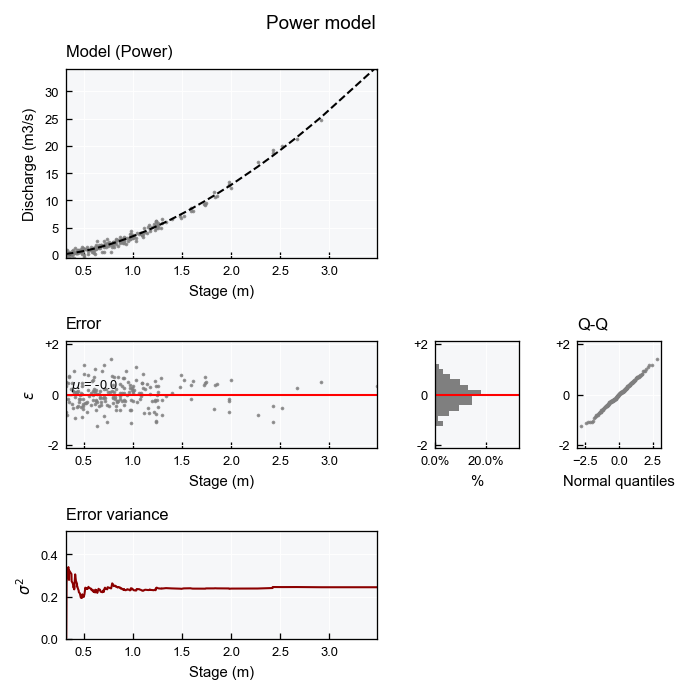

In [13]:
bv.view_specs["layout"] = "model"
bv.view_specs["model_type"] = "Power"
bv.view_specs["title"] = "Power model"
bv.view()

## Comparing models

Collect the metrics of all models in a table:

In [14]:
dc_metrics = {}
for model_type in bv.models:
    dc_metrics[model_type] = bv.models[model_type]["Metrics"]

df_metrics = pd.DataFrame(dc_metrics).T
df_metrics

,r,rho,R2,RMSE,MAE,Bias
Linear,0.962876,0.963426,0.927130,1.234986,0.919013,2.469679e-08
Power,0.994176,0.963426,0.988386,0.493044,0.395117,-5.401661e-02
Power_zero,0.993571,0.963426,0.986743,0.526753,0.407901,2.058272e+00


Note that $\rho$ is the same for all models: they are all increasing curves, so they rank the predictions in the same order. Here $r$, $R^2$ and the errors are what separate the models. Also, $R^2$ equals $r^2$ only for the least-squares linear model:

In [15]:
print(f"Linear R2: {df_metrics.loc['Linear', 'R2']:.4f}")
print(f"Linear r^2: {df_metrics.loc['Linear', 'r'] ** 2:.4f}")

Linear R2: 0.9271
Linear r^2: 0.9271


### Error normality

Assess if model errors are normal via the `.get_error_normality()` method:

In [16]:
ls_dfs = []
for model_type in bv.models:
    df = bv.get_error_normality(model_type=model_type, clevel=0.95)
    df.insert(0, "Model", model_type)
    ls_dfs.append(df)
pd.concat(ls_dfs, ignore_index=True)

,Model,Test,Statistic,p-value,is_normal,Confidence
0,Linear,Kolmogorov-Smirnov,0.084378,1.094225e-01,True,0.95
1,Linear,Shapiro-Wilk,0.876952,1.074658e-11,False,0.95
2,Linear,D'Agostino-Pearson,113.712185,2.031013e-25,False,0.95
3,Power,Kolmogorov-Smirnov,0.039072,9.083111e-01,True,0.95
4,Power,Shapiro-Wilk,0.997095,9.728016e-01,True,0.95
5,Power,D'Agostino-Pearson,0.095267,9.534831e-01,True,0.95
6,Power_zero,Kolmogorov-Smirnov,0.061591,4.172193e-01,True,0.95
7,Power_zero,Shapiro-Wilk,0.990347,2.006875e-01,True,0.95
8,Power_zero,D'Agostino-Pearson,0.870901,6.469732e-01,True,0.95


## Set parameters manually

Parameters can also be set by hand with `.update_model()`, for instance to test a known reference curve. Metrics and the model data are updated accordingly:

In [17]:
bv.update_model(params_mean=[-0.2, 1.6, 5.0], model_type="Power")
bv.models["Power"]["Metrics"]

{'r': 0.994033909930358,
 'rho': 0.9634260856521415,
 'R2': 0.9878227099891589,
 'RMSE': 0.5048491143405004,
 'MAE': 0.40285840445680393,
 'Bias': 0.8702160614684503}